IMPORT LIBRARIES


In [3]:
import pandas as pd  # work with data in tables
import numpy as np  # mathematical calculations and working with arrays
import matplotlib.pyplot as plt # creating graphs and charts

from sklearn.model_selection import train_test_split # Splits data into training and testing sets
from sklearn.preprocessing import StandardScaler # The numbers have very different ranges StandardScaler adjusting their valuesbetween 0 and 1
from sklearn.svm import SVC # svm = Support Vector Machine and SVC =  Support Vector Classifier .It is used to classify data into categories.Real-life example=emails SpamNot spam

from sklearn.metrics import(
    accuracy_score, # How many answers did the computer get correct?Imagine the computer looks at 10 animal pictures.Correct answers = 8Wrong answers = 2Accuracy = 8 out of 10 = 80%So, accuracy_score tells us the percentage of correct predictions.classification_report, # Give me a detailed report about the computer's answers.Imagine the computer identifies cats and dogs.This tool tells us:Precision: When the computer says "Cat," how often is it correct?Recall: How many of the actual cats did the computer identify?F1-score: A score that combines precision and recall.Support: How many actual cats and dogs were in the test data?
    confusion_matrix, #  Compares actual values with predicted values Creates a table comparing actual categories with predicted categories when classifying letters, it helps you see which letters the model classified correctly and which it confused with other letters.
    ConfusionMatrixDisplay #    Displays the confusion matrix as a graph  .when classifying letters, it helps you see which letters the model classified correctly and which it confused with other letters.
)




LOAD DATASET


In [4]:
data = pd.read_csv("letter-recognition.csv")
print(data)


      letter  xbox   ybox   width   height  onpix   xbar   ybar   x2bar  \
0          T      2      8       3       5       1      8     13      0   
1          I      5     12       3       7       2     10      5      5   
2          D      4     11       6       8       6     10      6      2   
3          N      7     11       6       6       3      5      9      4   
4          G      2      1       3       1       1      8      6      6   
...      ...    ...    ...     ...     ...     ...    ...    ...    ...   
19995      D      2      2       3       3       2      7      7      7   
19996      C      7     10       8       8       4      4      8      6   
19997      T      6      9       6       7       5      6     11      3   
19998      S      2      3       4       2       1      8      7      2   
19999      A      4      9       6       6       2      9      5      3   

       y2bar   xybar   x2ybar  xy2bar  xedge   xedgey  yedge   yedgex  
0           6       6      

CHECK DATASET

In [5]:
print("the shape of columns : \n")
print(data.shape)

print("dataset information : \n")
print("data.info")

print("check missing value : \n")
print(data.isnull)

the shape of columns : 

(20000, 17)
dataset information : 

data.info
check missing value : 

<bound method DataFrame.isnull of       letter  xbox   ybox   width   height  onpix   xbar   ybar   x2bar  \
0          T      2      8       3       5       1      8     13      0   
1          I      5     12       3       7       2     10      5      5   
2          D      4     11       6       8       6     10      6      2   
3          N      7     11       6       6       3      5      9      4   
4          G      2      1       3       1       1      8      6      6   
...      ...    ...    ...     ...     ...     ...    ...    ...    ...   
19995      D      2      2       3       3       2      7      7      7   
19996      C      7     10       8       8       4      4      8      6   
19997      T      6      9       6       7       5      6     11      3   
19998      S      2      3       4       2       1      8      7      2   
19999      A      4      9       6       6    

CHECK DUPLICATE VALUE

In [6]:
print("check duplicate value : \n ")
print(data.duplicated().sum())

check duplicate value : 
 
1332


TO REMOVE  OR DELETE DUPICATE VALUES

In [7]:
print("To remove duplicate value :\n")
print(data.drop_duplicates())

To remove duplicate value :

      letter  xbox   ybox   width   height  onpix   xbar   ybar   x2bar  \
0          T      2      8       3       5       1      8     13      0   
1          I      5     12       3       7       2     10      5      5   
2          D      4     11       6       8       6     10      6      2   
3          N      7     11       6       6       3      5      9      4   
4          G      2      1       3       1       1      8      6      6   
...      ...    ...    ...     ...     ...     ...    ...    ...    ...   
19994      T      5      8       7       7       7      7      9      4   
19995      D      2      2       3       3       2      7      7      7   
19996      C      7     10       8       8       4      4      8      6   
19997      T      6      9       6       7       5      6     11      3   
19999      A      4      9       6       6       2      9      5      3   

       y2bar   xybar   x2ybar  xy2bar  xedge   xedgey  yedge   yedgex 

UNDERSTAND THE TARGET COLUMN


In [8]:
print(data["letter"].unique())


<StringArray>
['T', 'I', 'D', 'N', 'G', 'S', 'B', 'A', 'J', 'M', 'X', 'O', 'R', 'F', 'C',
 'H', 'W', 'L', 'P', 'E', 'V', 'Y', 'Q', 'U', 'K', 'Z']
Length: 26, dtype: str


ACCESS X AND Y


In [9]:
x = data.drop("letter",axis = 1)    # letter col are target or output is remove for x bcs #  
y = data["letter"]
print(x.shape)
print(y.shape)

(20000, 16)
(20000,)


X AND Y IS TRAIN TEST AND SPLIT

The main purpose is to divide your data into training data and testing data.
Imagine you are teaching a computer to recognize handwritten letters, such as A, B, and C.
You have 100 pictures of letters.
- 80 pictures will be used to teach the computer.
- 20 pictures will be used to test whether the computer learned correctly.
This is what train_test_split() helps us do.

In [10]:
x_train, x_test, y_train, y_test = train_test_split(            #train = used for learning.  test = used for checking
    x,  # input features (the questions or information)
    y, # target labels (the correct answers).
    test_size=0.2,  # 20% testing 
    random_state=42, # real ex: random state divided there work into different part but result get random state 
    stratify=y #   Keep the class proportions similar in both sets .Helps keep the same balance of letters in the training and testing sets.
)




STANDARDSCALER USE TO DIFFERENT NUMERICAL VALUE INTO SIMALER SCALER

.shape tells you the size of your data.
For example, if you have a table with 80 rows and 3 columns:
x_train.shape
The output will be
(80, 3)

In [11]:
print("x_train : ",x_train.shape) # The number of rows and columns in the training input data.
print("x_test : ",x_test.shape)

print("y_train : ",y_train.shape) # The number of correct labels used for training.
print("y_test : ",y_test.shape)


x_train :  (16000, 16)
x_test :  (4000, 16)
y_train :  (16000,)
y_test :  (4000,)


FEATURE SCALING

fit means learn the scaling information from the training data, such as its mean and standard deviation.
transform means use that information to scale the training data  Interview answer: StandardScaler standardizes numerical features. We use fit_transform() on training data to learn and apply the scaling, and transform() on test data to apply the same scaling without data leakage.


In [ ]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train) #learns the scaling information and scales the training data.
x_test_j = scaler.transform(x_test ) # uses the scaling information already learned from x_train.

CREATE THE SVM MODEL

In [ ]:
model = SVC (
    
    kernel="rbf",  # Helps the model learn curved and complex patterns  #   RBF = Radial Basis Function.   It helps SVM handle data where the relationship between classes is not a simple straight line.  letters A, B, and C. Their numerical features may overlap, so separating them with a straight line
    C=10,  # Controls how strongly the model tries to avoid training mistakes
  #controls how much the model tries to avoid mistakes on the training data.
    gamma='scale' # scikit-learn calculates gamma automatically based on the training features, giving us a sensible starting point.

)

In [14]:
print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("X:", x.shape)
print("y:", y.shape)

x_train: (16000, 16)
y_train: (16000,)
X: (20000, 16)
y: (20000,)


In [15]:
model.fit(x_train,y_train) # Train the model


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


MAKE PREDICTIONS

You have already trained your SVM model using model.fit(x_train, y_train). Now, you are asking the model to predict answers and compare them with the actual answers.

In [16]:
y_pred = model.predict(x_test) # Make predictions

print("Actual values:")
print(y_test.values[:10])

print("Predicted values:")
print(y_pred[:10])

C:\Users\nayan\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


Actual values:
<StringArray>
['R', 'M', 'B', 'P', 'J', 'L', 'P', 'G', 'Z', 'V']
Length: 10, dtype: str
Predicted values:
['M' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'M' 'M']


CALCULATE ACCURACY


y_test = the real, correct answers.
y_pred = he answers predicted by your SVM model.
accuracy_score() = compares these two and calculates how many predictions are correct.

In [17]:
accuracy = accuracy_score(y_test, y_pred)

print("SVM Accuracy:", accuracy)
print("SVM Accuracy Percentage:", accuracy * 100, "%")
print(classification_report(y_test, y_pred))

SVM Accuracy: 0.0395
SVM Accuracy Percentage: 3.95 %


NameError: name 'classification_report' is not defined

DISPLAY CONFUSION MATRIX

The main purpose of this code is to create a Confusion Matrix. It helps you see which letters your SVM model predicts correctly and which letters it confuses with other letters.
Imagine the computer sees a picture of letter A, but predicts B. The confusion matrix helps you find that mistake

[[157   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   1   0]
 [  0 145   0   0   0   0   0   3   0   0   1   0   0   0   0   0   0   0
    2   0   0   2   0   0   0   0]
 [  0   0 144   0   1   0   0   0   0   0   0   0   0   0   2   0   0   0
    0   0   0   0   0   0   0   0]
 [  0   3   0 156   0   0   0   0   0   0   0   0   0   1   0   0   0   1
    0   0   0   0   0   0   0   0]
 [  0   1   1   0 150   0   1   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   1]
 [  0   0   0   0   0 153   0   1   0   1   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0]
 [  0   0   0   1   3   0 150   0   0   0   0   0   0   0   0   0   0   1
    0   0   0   0   0   0   0   0]
 [  0   1   0   4   0   0   1 135   0   0   1   0   0   0   0   0   0   5
    0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   1   0   0 141   8   0   0   0   0   0   0   0   0
    0   0   0   0   0   1   0   0]
 [  0   0   0   0  

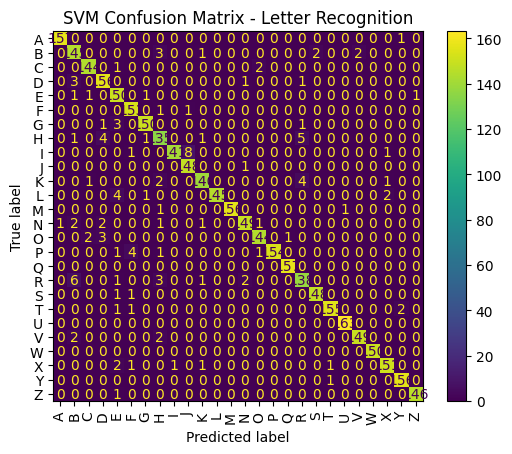

In [ ]:
cm = confusion_matrix(y_test, y_pred) #confusion_matrix() compares the actual answers with the predicted answers.
print(cm)
disp = ConfusionMatrixDisplay(  #visual display of the confusion matrix.
    confusion_matrix = cm,
    display_labels = model.classes_  #model.classes_ contains the class labels the model learned during training.
)

disp.plot(
    xticks_rotation="vertical")#This rotates the labels on the horizontal axis so they appear vertically.

plt.title("SVM Confusion Matrix - Letter Recognition")
plt.show()


TO PREDICT THE MODELS  BY GIVEN DATASET 


In [ ]:
sample = x_test.iloc[[0]] # Select the first row from the test data

prediction = model.predict(sample) # Ask the trained model to predict the letter
print("Predicted Letter:", prediction[0]) 
# Print the predicted letter

Predicted Letter: R


COMPARE ACTUAL DATA VS PREWDICTED LETTER


PREDICT MULTIPLE SAMPLE 

actual = y_test.iloc[0]
- y_test contains the correct answers for your test data.
- .iloc[0] selects the first correct answer.
- actual stores that answer.

In [ ]:
actual = y_test.iloc[0]

print("Actual Letter:", actual)
print("Predicted Letter:", prediction[0])


Actual Letter: R
Predicted Letter: R


: 